# Milestone 2: Data and Baseline Checkpoint
**Predicting whether a Steam game will be well received using only pre-release store information**

Kacper Konopka | 22357246 | CT4101 Machine Learning

## Aim
This notebook includes: the data audit, preprocessing pipeline, evaluation of design and a simple baseline mode for future milestones. The goal is to check that the workflow is reproducible and that the evaluation avoids data leakage.

## Contents
1. Provenance and setup
2. Unit of analysis and prediction moment
3. Data dictionary
4. Data audit (structure, types, missingness, duplicates, dates, invalid values and outliers)
5. Cleaning funnel and target definition
6. Evaluation design: time-based split
7. Target audit (on training and validation data only)
8. Leakage register
9. Preparation plan and engineered features
10. Baseline models and results
11. Reproducibility, findings and limitations

## 1. Provenance and setup
This section sets up the Imports, a fixed random seed and defines project settings.

**Decisions**
- Seed is fixed so results are the same on every run. (`SEED = 42`)
- Games with few reviews (`MIN_REVIEWS > 50`) are removed.
- Games with atleast 80% positive reviews (`POSITIVE_RATIO`) are considered *well-received* (for our prediction goal)
- Versions are printed for debugging purposes

In [2]:
import re, sys, random, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, recall_score,
                             precision_score, accuracy_score, brier_score_loss,
                             precision_recall_curve)

# Plotting and display settings
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False})
pd.options.display.max_columns = 50
pd.options.display.float_format = "{:,.3f}".format

# Random seed for reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Constants
MIN_REVIEWS = 50 # Min number of reviews for a game to be included in the dataset
POSITIVE_RATIO = 0.80 # Min ratio of positive reviews for a game to be included in the dataset
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15 # Fractions of the dataset to use for training and validation (the rest is used for testing)

# Data file path
DATA_PATH = next(p for p in [Path("data/games.csv"), Path("../data/games.csv")] if p.exists())

# Print versions of Python and libraries, and the data file path
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__)
print("Data file:", DATA_PATH.resolve())

Python 3.14.7 | pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1
Data file: C:\4BCT\Machine_Learning\GitRepo\data\games.csv


In [3]:
# Display provenance information (where data came from, who created it, when it was last modified, etc.)
provenance = pd.DataFrame({
    "item": ["Dataset", "Author", "Revision / year", "Publisher", "DOI", "Licence",
             "File retrieved (file date)", "Raw file size (MB)"],
    "value": ["Steam Games Dataset (FronkonGames/steam-games-dataset)", "Martin Bustos",
              "Revision c5b7f21, 2023", "Hugging Face", "10.57967/hf/0511", "MIT",
              datetime.datetime.fromtimestamp(DATA_PATH.stat().st_mtime).strftime("%Y-%m-%d"),
              round(DATA_PATH.stat().st_size / 1e6, 1)],
})
display(provenance)

,item,value
0,Dataset,Steam Games Dataset (FronkonGames/steam-games-...
1,Author,Martin Bustos
2,Revision / year,"Revision c5b7f21, 2023"
3,Publisher,Hugging Face
4,DOI,10.57967/hf/0511
5,Licence,MIT
6,File retrieved (file date),2026-10-21
7,Raw file size (MB),401.100


### Loading the raw data

`games.csv` has 40 fields per row.

*Problem found*: "Discount" and "DLC Count" get merged under one name in the header (`DiscountDLCcount`), if this is the case the data is shifted into the wrong place when it is loaded. This is dealt with by checking if the data has "DiscountDLC" count column and  assinging the 40 column names by itself.

In [4]:

RAW_COLUMNS = [
    "app_id", "name", "release_date", "estimated_owners", "peak_ccu", "required_age",
    "price", "discount", "dlc_count", "about_the_game", "supported_languages",
    "full_audio_languages", "reviews", "header_image", "website", "support_url",
    "support_email", "windows", "mac", "linux", "metacritic_score", "metacritic_url",
    "user_score", "positive", "negative", "score_rank", "achievements", "recommendations",
    "notes", "average_playtime_forever", "average_playtime_two_weeks",
    "median_playtime_forever", "median_playtime_two_weeks", "developers", "publishers",
    "categories", "genres", "tags", "screenshots", "movies",
]

# Load the dataset
header = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

# Check if the dataset has the "DiscountDLC count" column to determine how to read it
if "DiscountDLC count" in header:
    # If the dataset has the "DiscountDLC count" column, read it with the specified column names and skip the first row
    raw = pd.read_csv(DATA_PATH, header=None, skiprows=1, names=RAW_COLUMNS,
                      index_col=False, low_memory=False)
    
# If the dataset does not have the "DiscountDLC count" column, read it normally and clean up the column names
else:
    raw = pd.read_csv(DATA_PATH, low_memory=False)
    raw.columns = [c.strip().lower().replace(" ", "_") for c in raw.columns]
    raw = raw.rename(columns={"appid": "app_id"})

print(raw.shape)
raw[["app_id", "name", "release_date", "price", "windows", "positive", "negative"]].head()

(125855, 40)


,app_id,name,release_date,price,windows,positive,negative
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0.000,True,0,0
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",5.240,True,252,3
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",4.990,True,21,3
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",8.990,True,0,0
4,3631080,Maze Quest VR,"Apr 24, 2025",4.990,True,0,0


## 2. Unit Analysis and prediction moment ##

- One row = one Steam game (`app_id`)
- Prediction moment: the release date. Only info available on the store page when the game launched can be used.
- Target is observed after game launch. Games need atleast 50 reviews to be considered.
- Time structure: split is by `release_date`.
- Groups: devs release several games so rows are not fully independant. (this will be measured in section 6)

## 3. Data Dictionary: ##
Every column has a conceptual type, unit, role and its availabilty at prediction time.  

Values that may differ from the launch day store page are classified as "Risky"

In [5]:
# Display a dictionary of the columns in the dataset, including their conceptual type, unit, role, and availability at prediction time
dictionary = pd.DataFrame([
    ("app_id", "identifier", "-", "exclude (ID only)", "yes"), # app_id is an identifier and should be excluded from the model
    ("release_date", "temporal", "date", "split key + derived features", "yes"), # release_date is a temporal feature and can be used to split the dataset and derive features
    ("price", "numerical (continuous)", "USD, scrape-time price", "feature", "risky (may differ from launch price)"), # price is a numerical feature and can be used as a feature, but it may differ from the launch price
    ("required_age", "ordinal", "years", "feature", "yes"), # required_age is an ordinal feature and can be used as a feature
    ("dlc_count", "numerical (count)", "count", "feature (ablate)", "risky (can grow after launch)"), # dlc_count is a numerical feature and can be used as a feature, but it may grow after launch
    ("supported_languages", "multi-valued categorical", "list of languages", "feature (count, English flag)", "risky (languages added later)"), # supported_languages is a multi-valued categorical feature and can be used as a feature, but it may change after launch
    ("genres / categories", "multi-valued nominal", "list", "feature (multi-hot)", "mostly yes"), # genres and categories are multi-valued nominal features and can be used as features, but they may change after launch
    ("about_the_game", "text", "free text", "feature (TF-IDF, later)", "risky (can be edited)"), # about_the_game is a text feature and can be used as a feature, but it may be edited after launch
    ("windows / mac / linux", "binary", "flag", "feature", "yes"), # windows, mac, and linux are binary features and can be used as features
    ("positive, negative", "numerical (count)", "reviews", "used ONLY to build the target", "NO (post-launch)"), # positive and negative are numerical features that are used only to build the target variable and should not be used as features
    ("tags", "multi-valued nominal", "user-generated", "exclude", "NO (post-launch)"), # tags are multi-valued nominal features that should be excluded from the model
    ("metacritic_score", "numerical", "0-100 (0 = missing)", "exclude", "NO / mostly missing"), # metacritic_score is a numerical feature that should be excluded from the model because it is mostly missing
    ("estimated_owners, peak_ccu, recommendations, playtime columns", "numerical", "-", "exclude", "NO (post-launch)"), # estimated_owners, peak_ccu, recommendations, and playtime columns are numerical features that should be excluded from the model because they are post-launch metrics
    ("support_email, support_url, website, developers", "identifier / contact", "-", "exclude (privacy)", "yes, but personal data"), # support_email, support_url, website, and developers are identifiers or contact information that should be excluded from the model for privacy reasons
], columns=["column", "conceptual type", "unit", "role", "available at prediction time"])

display(dictionary)

,column,conceptual type,unit,role,available at prediction time
0,app_id,identifier,-,exclude (ID only),yes
1,release_date,temporal,date,split key + derived features,yes
2,price,numerical (continuous),"USD, scrape-time price",feature,risky (may differ from launch price)
3,required_age,ordinal,years,feature,yes
4,dlc_count,numerical (count),count,feature (ablate),risky (can grow after launch)
5,supported_languages,multi-valued categorical,list of languages,"feature (count, English flag)",risky (languages added later)
6,genres / categories,multi-valued nominal,list,feature (multi-hot),mostly yes
7,about_the_game,text,free text,"feature (TF-IDF, later)",risky (can be edited)
8,windows / mac / linux,binary,flag,feature,yes
9,"positive, negative",numerical (count),reviews,used ONLY to build the target,NO (post-launch)


## 4. Data Audit: ##
The purpose of the audit is to check the raw data before doing any modelling with it. The audit is descriptive only and no value is computed.

### 4.1 Structure

In [6]:
print("Shape:", raw.shape)

# Display a random sample of 5 rows from the dataset, showing the app_id, name, release_date, price, positive reviews, and negative reviews
display(raw.sample(5, random_state=SEED)[["app_id", "name", "release_date", "price", "positive", "negative"]])

# Display information about the dataset, including the number of non-null values and the data type of each column
raw.info(max_cols=50, show_counts=True)

Shape: (125855, 40)


,app_id,name,release_date,price,positive,negative
127,3400080,Fantasy Soul Revenge,"Dec 28, 2024",0.690,4,2
67814,2554950,Raioh,"Oct 6, 2023",3.490,17,0
29650,4025190,Ten Tek,"Oct 18, 2025",1.590,0,0
104535,472770,HELP: THE GAME,"Jul 26, 2016",14.990,9,0
51049,4129210,Hentai Travel,"Nov 21, 2025",2.990,0,0


<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   app_id                      125855 non-null  int64  
 1   name                        125854 non-null  str    
 2   release_date                125855 non-null  str    
 3   estimated_owners            125855 non-null  str    
 4   peak_ccu                    125855 non-null  int64  
 5   required_age                125855 non-null  int64  
 6   price                       125855 non-null  float64
 7   discount                    125855 non-null  int64  
 8   dlc_count                   125855 non-null  int64  
 9   about_the_game              117393 non-null  str    
 10  supported_languages         125855 non-null  str    
 11  full_audio_languages        125855 non-null  str    
 12  reviews                     12181 non-null   str    
 13  header_image             

In [7]:
# Display the columns with the most missing values (as a share of total rows) and the columns with the fewest distinct values
print("Columns with the most missing values (share):")
display(raw.isna().mean().sort_values(ascending=False).head(15).to_frame("missing_share"))

# Display the columns with the fewest distinct values
print("Columns with the fewest distinct values:")
display(raw.nunique().sort_values().head(12).to_frame("n_unique"))

Columns with the most missing values (share):


,missing_share
movies,1.000
score_rank,1.000
metacritic_url,0.966
reviews,0.903
notes,0.815
website,0.599
support_url,0.561
tags,0.338
support_email,0.180
categories,0.071


Columns with the fewest distinct values:


,n_unique
movies,0
mac,2
windows,2
linux,2
score_rank,3
estimated_owners,14
required_age,15
user_score,31
metacritic_score,73
discount,88


### 4.2 Storage type or conceptual type

Check the data types, number of unique values and an example value for the selected columns.

In [8]:
# Display the data types, number of unique values, and an example value for selected columns in the dataset
cols = ["app_id", "release_date", "price", "required_age", "windows", "supported_languages",
        "genres", "categories", "positive", "about_the_game"]
types_tbl = pd.DataFrame({
    "stored dtype": raw[cols].dtypes.astype(str),
    "n_unique": raw[cols].nunique(),
    "example": raw[cols].iloc[0].astype(str).str.slice(0, 40),
})
display(types_tbl)

,stored dtype,n_unique,example
app_id,int64,125855,2539430
release_date,str,5141,"Aug 1, 2023"
price,float64,953,0.0
required_age,int64,15,0
windows,bool,2,True
supported_languages,str,19614,[]
genres,str,2922,NaN
categories,str,14058,NaN
positive,int64,5541,0
about_the_game,str,116776,NaN


**Findings**
- Raw file has 125,855 rows and 40 columns.
- `release_date` is stored as a string - every value parses.
- `app_id` is stored as an int but is an identifier.
- `genres`, `categories` and `supported_languages` are stored as strings. They are split into separate values.
- `windows`, `mac` and `linux` are booleans and are converted to 0/1.

### 4.3 Missing values, zeros and empty lists
In games.csv some numeric columns use `0` to show that there is no value there rather than using a real zero. (these do not count as missing)

In [9]:
# Display the number of unparseable release dates, the range of release dates, and the number of future release dates
num_cols = ["price", "required_age", "dlc_count", "metacritic_score", "positive",
            "negative", "achievements", "recommendations"]
num = raw[num_cols].apply(pd.to_numeric, errors="coerce")
audit = pd.DataFrame({
    "missing_%": (num.isna().mean() * 100).round(1),
    "zero_%": ((num == 0).mean() * 100).round(1),
})
display(audit)

def is_empty(s):
    return s.isna() | s.astype(str).str.strip().isin(["", "[]", "nan"])

# Display the percentage of empty values for selected columns in the dataset
list_cols = ["categories", "genres", "tags", "supported_languages", "developers",
             "publishers", "about_the_game", "name"]
empty_tbl = pd.DataFrame({c: [is_empty(raw[c]).mean() * 100] for c in list_cols}).T
empty_tbl.columns = ["empty_%"]
display(empty_tbl.round(1))

,missing_%,zero_%
price,0.000,21.200
required_age,0.000,99.000
dlc_count,0.000,85.700
metacritic_score,0.000,96.600
positive,0.000,36.200
negative,0.000,46.400
achievements,0.000,48.600
recommendations,0.000,83.300


,empty_%
categories,7.100
genres,6.700
tags,33.800
supported_languages,6.700
developers,6.700
publishers,7.100
about_the_game,6.700
name,0.000


**Findings**
- `metacritic_score` is 0 for **96.6%** of games. This means "no score", i.e. **missing**, not a real score of zero.
- Some zeros are valid values: `price` is 0 for 21.20% of games (these are free), `required_age` is 0 for 99.00% (games with no age restriction set) and `dlc_count` is 0 for 85.70% (game has no DLC).
- `positive` is 0 for 36.20% and `negative` is 0 for 46.40% of games. Many games have few or no reviews.
- Some columns are completely empty or have very little values. `movies` 100% missing, `score_rank` 99.97%, `metacritic_url` 96.60%, `reviews` 90.30%, `notes` 81.50%, `website` 59.90%, `support_url` 56.10%.
- `tags` are empty for 33.80% of games. `genres`, `about_the_game`, `developers` and `supported_languages` are each empty for 6.70%, and `categories` and `publishers` for 7.10%. The identical 6.70% across four columns suggests the same entries.

**Why are values missing?**
- `metacritic_score`: Only some games are reviewed by critics, and that depends on how well known the game is.
- Empty store-page fields: depends on the type of entry (no real store page), not on random gaps.
- `tags`: these are user-generated, so unpopular games have very little.

**Decisions**
- `metacritic_score`, `tags`, review text and the other mostly-empty or post-release columns are excluded.
- Entries that do not have a real description (under 20 characters) are removed in the cleaning funnel.
- Zeros that are valid values (price, age, DLC) are kept as they are.
- To handle gaps numerical features will use median imputation fitted on the training data, with a missing-value indicator.

### 4.4 Duplicates
Checking levels for duplicates.

In [10]:
# Display the number of duplicate rows in the dataset, as well as the number of rows that have the same app_id or the same (name, release_date, developers) combination
print("Exact duplicate rows:            ", raw.duplicated().sum())
print("Duplicate app_id:                ", raw.duplicated("app_id").sum())
print("Same (name, release_date, dev):  ", raw.duplicated(["name", "release_date", "developers"]).sum())

# Display the number of rows that have the same normalized name and release date, as well as the number of rows that share the same developer and identical description (near-duplicates)
norm_name = raw["name"].astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
print("Same normalised name + date:     ", pd.DataFrame({"n": norm_name, "d": raw["release_date"]}).duplicated().sum())

# Display the number of rows that share the same developer and identical description (near-duplicates), which may indicate demos or bundles
has_desc = raw["about_the_game"].fillna("").astype(str).str.len() >= 20
near = raw[has_desc].duplicated(["developers", "about_the_game"], keep=False)
print("Rows sharing developer + identical description (near-duplicates, e.g. demos/bundles):", near.sum())
display(raw.loc[has_desc][near.values][["name", "release_date", "developers"]].head(8))

Exact duplicate rows:             0
Duplicate app_id:                 0
Same (name, release_date, dev):   111
Same normalised name + date:      965
Rows sharing developer + identical description (near-duplicates, e.g. demos/bundles): 796


,name,release_date,developers
27,Lucky Night: Texas Hold'em VR,"Jul 26, 2017",ATC Games
67,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018","Eidos-Montréal,Crystal Dynamics,Nixxes,Feral I..."
135,go cycling,"Aug 9, 2025",hgmGame
257,Aery VR - A Journey Beyond Time,"Mar 24, 2023",EpiXR Games UG
299,Hentai Sexy,"Jul 31, 2021",Reddiamondgames
331,Hidden Industries Top-Down 3D,"Jun 18, 2022",Top-Down Games
372,Hentai Neon Nights,"Sep 22, 2023",Slippy Floor
728,Naga Girls,"Oct 25, 2023",IR Studio


**Findings**:
- No exact duplicate rows found and no duplicate `app_id` found.
- 111 rows share the same (name, release date, developers) as another row, and 965 share the same normalised name and release date.
- 796 rows share the same developer and an identical description. (different editions of same game?)

**Decisions**:
- `app_id` defines identity. Duplicates are dropped on `app_id` first.
- Duplicates on (name, release date, developers) will be checked again after filtering, because filtering can change which rows remain (79 were removed in the cleaning funnel).
- Near-duplicates are kept since they are separate entries and not errors. This will be recorded as a limitation in the system.

### 4.5 Release dates, review counts and distributions

Unparseable release dates: 0
Release range: 1997-06-30 -> 2026-12-01
Future release dates: 1
Games with zero reviews: 42,899 (34.1%)
Games with >= 50 reviews: 30,624 (24.3%)


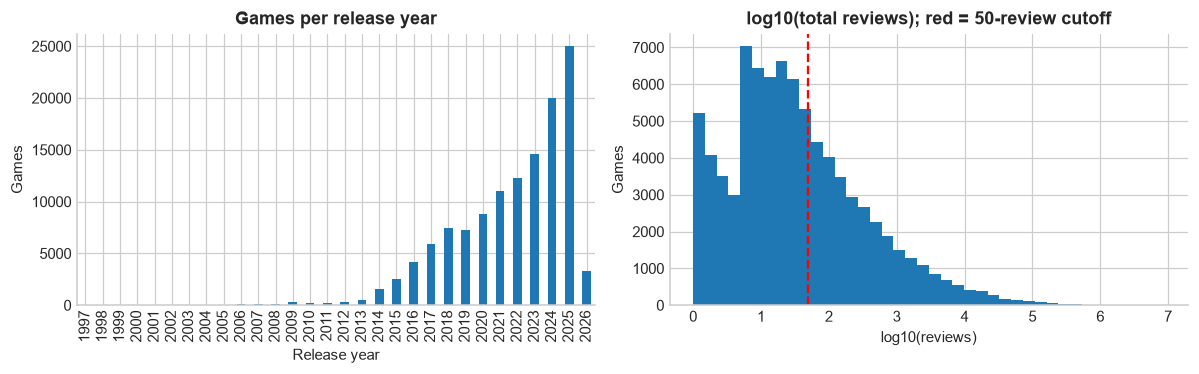

In [11]:
# Display the number of unparseable release dates, the range of release dates, and the number of future release dates
rd = pd.to_datetime(raw["release_date"], errors="coerce")
print("Unparseable release dates:", rd.isna().sum())
print("Release range:", rd.min().date(), "->", rd.max().date())
print("Future release dates:", (rd > pd.Timestamp.today()).sum())

# Calculate the total number of reviews for each game and display the number of games with zero reviews and the number of games with at least MIN_REVIEWS reviews
n_rev = num["positive"].fillna(0) + num["negative"].fillna(0)
print(f"Games with zero reviews: {(n_rev == 0).sum():,} ({(n_rev == 0).mean():.1%})")
print(f"Games with >= {MIN_REVIEWS} reviews: {(n_rev >= MIN_REVIEWS).sum():,} ({(n_rev >= MIN_REVIEWS).mean():.1%})")

# Display a bar chart of the number of games released per year and a histogram of the log10 of the total number of reviews for each game, with a red dashed line indicating the MIN_REVIEWS cutoff
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
rd.dt.year.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Games per release year")
ax[0].set_xlabel("Release year"); ax[0].set_ylabel("Games")
np.log10(n_rev[n_rev > 0]).hist(bins=40, ax=ax[1])
ax[1].axvline(np.log10(MIN_REVIEWS), color="red", ls="--")
ax[1].set(title="log10(total reviews); red = 50-review cutoff", xlabel="log10(reviews)", ylabel="Games")
plt.tight_layout(); plt.show()

**Findings:**
- All 125,855 release dates parse. They range from 1997-06-30 to 2026-12-01, and 1 game has a future release date (removed in the funnel).
- 34.1% of games have zero reviews and only 24.3% of games have at least 50 reviews, so the cutoff removes about three-quarters of the data.
- The number of games released per year grows steadily and peaks in 2025.

**Implication:** the mix of games changes a lot over time, so a random split would let the model learn from the future. A time-based split is used.

### 4.6 Invalid values and outliers
Approach: **detect, interpret, act, document.** 
The thresholds below are starting points for the investigation.

In [12]:
# Check for data quality issues in the dataset, such as negative prices, required ages outside the range of 0-21, and negative review counts. Display a summary of the issues found and a sample of rows that violate the rules.
chk = raw.copy()
chk["release_date"] = pd.to_datetime(chk["release_date"], errors="coerce")
for c in ["price", "required_age", "dlc_count", "positive", "negative"]:
    chk[c] = pd.to_numeric(chk[c], errors="coerce")

display(chk[["price", "required_age", "dlc_count", "positive", "negative"]]
        .describe(percentiles=[.01, .5, .99]).T)

# Define rules to check for data quality issues in the dataset, such as negative prices, required ages outside the range of 0-21, and negative review counts. Create a DataFrame summarizing the number of rows affected by each rule and display it. Also, display a sample of rows that violate the "price > 100" rule for inspection.
rules = {
    "price < 0": chk["price"] < 0,
    "price > 100 (inspect)": chk["price"] > 100,
    "required_age outside 0-21": ~chk["required_age"].between(0, 21),
    "dlc_count > 100 (inspect)": chk["dlc_count"] > 100,
    "negative review counts": (chk["positive"] < 0) | (chk["negative"] < 0),
    "release year before 2000 (inspect)": chk["release_date"].dt.year < 2000,
}
# Create a DataFrame summarizing the number of rows affected by each rule and display it
issues = pd.DataFrame({"rule": list(rules), "rows_affected": [int(m.sum()) for m in rules.values()]})
display(issues)

# Display a sample of rows that violate the "price > 100" rule for inspection, showing the name and price of the games
display(chk.loc[rules["price > 100 (inspect)"], ["name", "price"]].head(8))

,count,mean,std,min,1%,50%,99%,max
price,"125,855.000",4.811,12.489,0.000,0.000,2.390,29.990,999.980
required_age,"125,855.000",0.165,1.643,0.000,0.000,0.000,10.000,21.000
dlc_count,"125,855.000",0.535,14.328,0.000,0.000,0.000,7.000,"3,703.000"
positive,"125,855.000","1,018.182","27,727.824",0.000,0.000,4.000,"12,869.520","7,642,084.000"
negative,"125,855.000",164.879,"5,305.001",0.000,0.000,1.000,"2,068.000","1,173,003.000"


,rule,rows_affected
0,price < 0,0
1,price > 100 (inspect),317
2,required_age outside 0-21,0
3,dlc_count > 100 (inspect),39
4,negative review counts,0
5,release year before 2000 (inspect),5


,name,price
331,Hidden Industries Top-Down 3D,199.990
2035,Knights Shadow,199.990
2476,眼睛（眼球）结构研究,199.990
3154,Bounce racing car,199.990
4176,Hidden Farm 2 Top-Down 3D,199.990
4235,Bicycle Challenge - Wastelands,199.990
4572,Reincarnation of Ocean,199.990
4618,Hidden World 5 Top-Down 3D,199.990


- price < 0 - 0 affected (no negative values) - no action needed
- price > 100 - 317 found - kept
- required_age outside 0-21 - 0 found - no action needed
- dlc_count > 100 - 39 found - kept
- negative review counts - 0 found - none needed
- release year before 2000 - 5 found - kept

Outliers are not dropped just because they might hurt accuracy.


## 5. Cleaning funnel and target definition
Rows are removed and counted. The filters are based on the rules set.

The target is `well_received = positive / (positive + negative) >= 0.80`, for games with at least 50 reviews. `positive` and `negative` are used only to build this label.

`dev_prior_games` (number of earlier releases by the same developer) is computed before the review filter, so it counts all earlier releases, and uses only earlier release dates.

In [13]:
def to_list(s):
    if pd.isna(s): return []
    s = str(s).strip()
    if s.startswith("["):
        return [a or b for a, b in re.findall(r"'([^']+)'|\"([^\"]+)\"", s)]
    return [x.strip() for x in s.split(",") if x.strip()]

# Data cleaning and feature engineering
funnel = [("raw rows", len(raw))]
def step(name, d):
    funnel.append((name, len(d))); return d

# Perform data cleaning and feature engineering on the raw dataset, including dropping duplicates, converting data types, filtering rows based on various criteria, and creating new features based on existing columns. The resulting DataFrame is stored in the variable `df`.
df = step("drop duplicate app_id", raw.drop_duplicates("app_id").copy())
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
for c in ["price", "positive", "negative", "required_age", "dlc_count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = step("valid date / price / review counts", df.dropna(subset=["release_date", "price", "positive", "negative"]))
df = step("non-negative price and review counts", df[(df["price"] >= 0) & (df["positive"] >= 0) & (df["negative"] >= 0)])
df = step("already released", df[df["release_date"] <= pd.Timestamp.today()])
df["about_the_game"] = df["about_the_game"].fillna("").astype(str).str.strip()
df = step("has a description (>= 20 chars)", df[df["about_the_game"].str.len() >= 20])

# Create new features based on existing columns, such as the number of prior games by the same developer, whether the game is self-published, the total number of reviews, whether the game is well-received, and various pre-release features such as release month and year, number of supported languages, and whether the game supports English. Also create binary features for whether the game supports Windows, Mac, and Linux, and fill missing values for required_age and dlc_count with 0. Finally, create string representations of genres and categories, extract the primary genre, and determine whether the description is in Latin or non-Latin script.
df = df.sort_values("release_date")
dev_key = df["developers"].map(lambda s: (to_list(s) or [""])[0].lower())
pub_key = df["publishers"].map(lambda s: (to_list(s) or [""])[0].lower())
df["dev_prior_games"] = np.where(dev_key == "", 0, df.groupby(dev_key).cumcount())
df["self_published"] = ((dev_key == pub_key) & (dev_key != "")).astype(int)

# Create a new column "n_reviews" that is the sum of the "positive" and "negative" review counts for each game. Then filter the DataFrame to only include games with at least MIN_REVIEWS reviews, and drop duplicates based on the combination of "name", "release_date", and "developers". Finally, create a new binary column "well_received" that indicates whether the ratio of positive reviews to total reviews is greater than or equal to POSITIVE_RATIO.
df["n_reviews"] = df["positive"] + df["negative"]
df = step(f">= {MIN_REVIEWS} reviews", df[df["n_reviews"] >= MIN_REVIEWS])
df = step("drop duplicates after filtering", df.drop_duplicates(["name", "release_date", "developers"]))

df["well_received"] = (df["positive"] / df["n_reviews"] >= POSITIVE_RATIO).astype(int)

# Pre-release features
df["release_month"] = df["release_date"].dt.month
df["release_year"] = df["release_date"].dt.year
langs = df["supported_languages"].map(to_list)
df["n_languages"] = langs.map(len)
df["supports_english"] = langs.map(lambda l: int(any("english" in x.lower() for x in l)))
for c in ["windows", "mac", "linux"]:
    df[c] = df[c].astype(str).str.strip().str.lower().eq("true").astype(int)
df["required_age"] = df["required_age"].fillna(0)
df["dlc_count"] = df["dlc_count"].fillna(0)
df["genres_str"] = df["genres"].map(lambda s: ",".join(to_list(s)))
df["categories_str"] = df["categories"].map(lambda s: ",".join(to_list(s)))
df["primary_genre"] = df["genres_str"].map(lambda s: s.split(",")[0] if s else "Unknown")
ascii_r = df["about_the_game"].map(lambda t: sum(ch.isascii() for ch in t) / len(t))
df["desc_script"] = np.where(ascii_r >= 0.9, "latin", "non_latin")

df = df.sort_values("release_date").reset_index(drop=True)

# Display the funnel of data cleaning and feature engineering steps, showing the number of rows remaining after each step and the number of rows removed at each step. Also display the class balance of the target variable "well_received".
funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
funnel_df["removed"] = (-funnel_df["rows"].diff()).fillna(0).astype(int)
display(funnel_df)
print("\nClass balance (well_received):")
print(df["well_received"].value_counts(normalize=True).round(3))

,step,rows,removed
0,raw rows,125855,0
1,drop duplicate app_id,125855,0
2,valid date / price / review counts,125855,0
3,non-negative price and review counts,125855,0
4,already released,125854,1
5,has a description (>= 20 chars),117372,8482
6,>= 50 reviews,30554,86818
7,drop duplicates after filtering,30475,79



Class balance (well_received):
well_received
1   0.552
0   0.448
Name: proportion, dtype: float64


**Findings:** 
- 30,475 rows (24.2% of the raw file) remain after cleaning.
- 55.2% well received, 44.8% not well received.

## 6. Evaluation design: time-based split
This step follows the safe ordering (split first, then learn preprocessing from the training data only):

- **Time-based split by release date:** oldest 70% = train, next 15% = validation, newest 15% = test. Used to predict newer games from older ones.
- **Validation** is used to choose the decision threshold. The*test set is scored once, at the end.
- **Positive class** for PR-AUC, F1 and recall is the minority class.
- **Main metric:** PR-AUC. Also reported: F1 and recall, ROC-AUC, Brier score and calibration error (ECE). Accuracy is for context only.
- **No cross-validation used yet:** A single chronological train/validation/test split is used instead. (so games dont get mixed)

In [14]:
# Split the data into train, validation, and test sets
n = len(df)
i1, i2 = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
train, val, test = df.iloc[:i1].copy(), df.iloc[i1:i2].copy(), df.iloc[i2:].copy()

assert train["release_date"].max() <= val["release_date"].min()
assert val["release_date"].max() <= test["release_date"].min()
assert not (set(train["app_id"]) & set(test["app_id"])) and not (set(train["app_id"]) & set(val["app_id"]))

# Display information about each split
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} n={len(part):6d}  {part['release_date'].min().date()} -> {part['release_date'].max().date()}"
          f"  well_received={part['well_received'].mean():.3f}")

# Check for developer overlap between splits
shared_dev = set(train["developers"].map(lambda s: (to_list(s) or [""])[0])) & \
             set(test["developers"].map(lambda s: (to_list(s) or [""])[0])) - {""}
print(f"\nDevelopers appearing in both train and test (group overlap): {len(shared_dev):,}")

# Determine the minority class for evaluation metrics
pos_label = int(train["well_received"].value_counts().idxmin())
print("Minority class (positive for PR-AUC / F1 / recall):", pos_label)
to_y = lambda d: (d["well_received"] == pos_label).astype(int).values
y_train, y_val, y_test = to_y(train), to_y(val), to_y(test)

train n= 21332  1997-06-30 -> 2022-04-22  well_received=0.507
val   n=  4571  2022-04-24 -> 2024-01-23  well_received=0.624
test  n=  4572  2024-01-23 -> 2025-12-23  well_received=0.684

Developers appearing in both train and test (group overlap): 1,043
Minority class (positive for PR-AUC / F1 / recall): 0


**Findings:**
- Train: 21,332 games (1997-06-30 to 2022-04-22). Validation: 4,571 (2022-04-24 to 2024-01-23). Test: 4,572 (2024-01-23 to 2025-12-23).
-`well-received` games rise over time. 50.7% -> 62.4% -> 68.4%
- Minority class in the training data is 0 (not well received). 49.3% of train, only 37.6% of validation and 31.6% of test. So PR-AUC, F1 and recall measure how well *poorly received* games are ident
 - 1043 developers appear in both train and test. The time split only partly limits this, so it is recorded as a leakage risk.

## 7. Target audit
This section uses training and validation data only, so the test period is not examined before the final evaluation.

- **Observed:** After launch. reviews are accumulated over time.
- **Selection effect:** only games with at least 50 reviews are kept. (removing outliers)
- **Proxy:** the label measures player opinion, not quality

Share of games reaching 50 reviews, by release year (up to end of validation period):


,share_kept
year,
2013,0.925
2014,0.898
2015,0.756
2016,0.620
2017,0.454
2018,0.364
2019,0.335
2020,0.312
2021,0.232


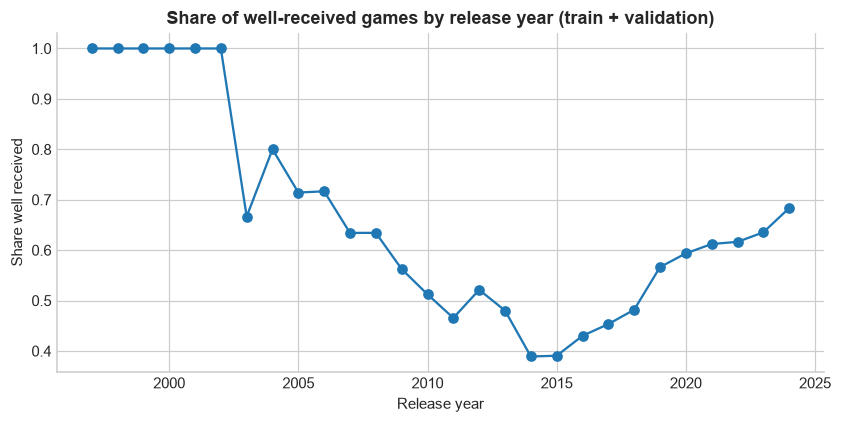

Share of training games within +/-0.05 of the 0.80 cutoff: 24.7%
Prevalence of well_received at other thresholds (training data):
  threshold 0.70: 0.713
  threshold 0.80: 0.507
  threshold 0.90: 0.227


In [15]:
# Analyze drift in the target variable
cut = val["release_date"].max()
seen = (rd <= cut).values
sel = pd.DataFrame({"year": rd[seen].dt.year.values, "kept": (n_rev >= MIN_REVIEWS)[seen].values})
print("Share of games reaching 50 reviews, by release year (up to end of validation period):")
display(sel.groupby("year")["kept"].mean().round(3).tail(12).to_frame("share_kept"))

# Analyze drift in the target variable
trval = pd.concat([train, val])
drift = trval.groupby("release_year")["well_received"].agg(["mean", "size"])
ax = drift["mean"].plot(marker="o", title="Share of well-received games by release year (train + validation)")
ax.set_xlabel("Release year"); ax.set_ylabel("Share well received"); plt.show()

# Analyze the distribution of the target variable across different review thresholds
ratio = train["positive"] / train["n_reviews"]
print(f"Share of training games within +/-0.05 of the 0.80 cutoff: {ratio.between(0.75, 0.85).mean():.1%}")
print("Prevalence of well_received at other thresholds (training data):")
for t in (0.70, 0.80, 0.90):
    print(f"  threshold {t:.2f}: {(ratio >= t).mean():.3f}")

**Findings**
- **Selection effect**: The number of games that reach 50 reviews fall at the steady rate with the release year: 92.5% (2013), 45.4% (2017), 31.2% (2020) and 16.2% (2024). Recent games in the data are therefore the ones that attracted enough players, which explains why their ratings are higher.
- **Label drift:** the share of well-received games falls from about 70% in the mid-2000s to about 39% in 2014-2015, then rises steadily to about 68% in 2024 (the very first years contain only a few games). A model trained on older games sees a different class balance from the test period, which is why calibration is expected to be affected (section 10).
- **Label noise:** 24.7% of training games lie within 0.05 of the 0.80 cutoff, so small changes in reviews can flip their label. Moving the cutoff changes the prevalence a lot: 71.3% well received at 0.70, 50.7% at 0.80 and 22.7% at 0.90. The 0.80 cutoff from the proposal is kept.

**Limitations:** the target is a proxy for player opinion (review-bombing and adult content can affect it), and games with few reviews are absent from the labelled data.



## 8. Leakage register

This part registers three leakage risks. It records the risk, its type and why it leaks and the mitigation.

**Checks done**
 - Split is chronological and assesrtions confirm the three parts are in time order (train -> validation -> test) and that no `app_id` in train also appears in validation or test.
 - Assertions confirm that no banned (post-release or contact) column is used as a feature.
- Every learned step is fitted on training data only

In [16]:
# Identify and document potential sources of leakage
leakage = pd.DataFrame([
    ("positive / negative / recommendations / user_score", "Target leakage", "Directly encode the outcome", "Used only to build the label, never as features (assertion below)"),
    ("tags", "Target leakage", "User-generated after launch; reflect reception", "Excluded"),
    ("estimated_owners, peak_ccu, playtime columns", "Target leakage", "Post-launch popularity correlates with reviews", "Excluded"),
    ("dlc_count, achievements", "Target leakage (mild)", "May have been updated after launch", "achievements excluded; dlc_count kept as a flagged feature and ablated"),
    ("price, languages, description, genres", "Snapshot leakage", "File was scraped at one time; values may differ from the launch-day page", "Kept (needed for the question); documented as a limitation"),
    ("same developer in train and test", "Group leakage", "Developer quality carries across a developer's games", "Time split limits it; developer history uses past data only; report developer-size subgroup"),
    ("random split", "Temporal leakage", "Future games would inform predictions about the past", "Time-based split by release date"),
    ("scaler / imputer / vocabulary fitted on all data", "Train-test contamination", "Test statistics would shape the representation", "All learned preprocessing is inside sklearn Pipelines fitted on train only"),
], columns=["column / issue", "type", "why it leaks", "mitigation"])
display(leakage)

# Define lists of columns that are banned from use due to potential leakage
POST_RELEASE_BANNED = ["positive", "negative", "recommendations", "user_score", "metacritic_score",
                       "estimated_owners", "peak_ccu", "score_rank", "reviews", "tags", "achievements",
                       "average_playtime_forever", "average_playtime_two_weeks",
                       "median_playtime_forever", "median_playtime_two_weeks", "n_reviews", "well_received"]
CONTACT_BANNED = ["support_email", "support_url", "website", "developers", "publishers", "name"]

,column / issue,type,why it leaks,mitigation
0,positive / negative / recommendations / user_s...,Target leakage,Directly encode the outcome,"Used only to build the label, never as feature..."
1,tags,Target leakage,User-generated after launch; reflect reception,Excluded
2,"estimated_owners, peak_ccu, playtime columns",Target leakage,Post-launch popularity correlates with reviews,Excluded
3,"dlc_count, achievements",Target leakage (mild),May have been updated after launch,achievements excluded; dlc_count kept as a fla...
4,"price, languages, description, genres",Snapshot leakage,File was scraped at one time; values may diffe...,Kept (needed for the question); documented as ...
5,same developer in train and test,Group leakage,Developer quality carries across a developer's...,Time split limits it; developer history uses p...
6,random split,Temporal leakage,Future games would inform predictions about th...,Time-based split by release date
7,scaler / imputer / vocabulary fitted on all data,Train-test contamination,Test statistics would shape the representation,All learned preprocessing is inside sklearn Pi...


## 9. Preparation plan and engineered features

### Preprocessing pipeline (fitted on training data)
| Type | Columns | Treatment | Reason |
|---|---|---|---|
| Numerical | price, required_age, dlc_count, n_languages, dev_prior_games, month_sin, month_cos | median imputation with missing indicator, then standardisation | median is robust; the scale of the features differs |
| Binary | windows, mac, linux, supports_english, self_published | passed through | already 0/1 |
| Multi-valued nominal | genres, categories | multi-hot encoding; levels in fewer than 50 training games are dropped (`min_df=50`); unseen values at prediction time are ignored | a game can have several genres; no false order is created |
| Identifier / personal | app_id, name, developers, publishers, contact fields | excluded | no generalisable signal; privacy |
| Text | about_the_game | not used yet (TF-IDF in a later milestone) | compared with and without text later |

`release_year` is **not** used as a feature: with a time split the test years are never seen in training, so a year feature cannot generalise. `LabelEncoder` is not used on inputs because it would invent an order between genres.

### Engineered features (hypotheses to test, not assumed useful)
1. **Release month as sine/cosine** (`month_sin`, `month_cos`): launch timing around holidays and Steam sales may matter, and December is next to January. Available at launch.
2. **`dev_prior_games`** (number of earlier releases by the same developer): a proxy for studio experience. Available at launch, because it uses only earlier release dates.

### Check
Pipeline is fitted on the training data and then applied to all three splits. The output has the same number of columns (82) for train, validation and test, so the representation learned from the training data applies consistently. The baselines below use only price and genre; the full pipeline is used by the models in the next milestone.

**Note:** the baseline applies `log1p` to price before scaling because price is long-tailed, since the full pipeline currently only standardises it.

In [17]:
# Define a function to add derived features to the dataset, including sine and cosine transformations of the release month to capture seasonality effects.
def add_features(d):
    d = d.copy()
    d["month_sin"] = np.sin(2 * np.pi * d["release_month"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["release_month"] / 12)
    return d

# Define a function to split a string by commas and strip whitespace from each element, returning a list of non-empty elements.
def split_commas(s):
    return [t.strip() for t in str(s).split(",") if t.strip()]

# Define a function to create a multi-hot encoding vectorizer for categorical features, using the CountVectorizer from scikit-learn with a custom tokenizer that splits by commas. The resulting vectorizer will produce binary features indicating the presence or absence of each category, and will ignore categories that appear in fewer than `min_df` documents.
def multi_hot(min_df=50):
    return CountVectorizer(tokenizer=split_commas, token_pattern=None, lowercase=False,
                           binary=True, min_df=min_df)

# Define lists of numerical and binary columns to be used as features, and combine them into a full list of features. Assert that there is no overlap between the full feature list and the banned columns to prevent leakage.
NUM_COLS = ["price", "required_age", "dlc_count", "n_languages", "dev_prior_games", "month_sin", "month_cos"]
BIN_COLS = ["windows", "mac", "linux", "supports_english", "self_published"]
FULL_FEATURES = NUM_COLS + BIN_COLS + ["genres_str", "categories_str"]
assert not set(FULL_FEATURES) & set(POST_RELEASE_BANNED + CONTACT_BANNED), "leakage!"

# Define a ColumnTransformer to preprocess the features, including imputing missing values for numerical features, scaling them, passing through binary features, and applying multi-hot encoding to the genres and categories string features.
prep_full = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("genres", multi_hot(), "genres_str"),
    ("cats", multi_hot(), "categories_str"),
])

# Fit the preprocessing pipeline on the training data and transform the train, validation, and test sets. Print the output shapes of the transformed datasets and display an example of the feature names generated by the preprocessing pipeline.
train_f, val_f, test_f = add_features(train), add_features(val), add_features(test)
prep_full.fit(train_f[FULL_FEATURES])                       # learned from TRAIN only
shapes = {k: prep_full.transform(d[FULL_FEATURES]).shape for k, d in
          [("train", train_f), ("val", val_f), ("test", test_f)]}
print("Output shapes (rows, features):", shapes)
try:
    print("Example feature names:", list(prep_full.get_feature_names_out())[:12])
except Exception as e:
    print("Feature names unavailable:", e)

Output shapes (rows, features): {'train': (21332, 82), 'val': (4571, 82), 'test': (4572, 82)}
Example feature names: ['num__price', 'num__required_age', 'num__dlc_count', 'num__n_languages', 'num__dev_prior_games', 'num__month_sin', 'num__month_cos', 'bin__windows', 'bin__mac', 'bin__linux', 'bin__supports_english', 'bin__self_published']


## 10. Baseline models
1. **Majority-class predictor** (always predicts the majority class).
2. **Logistic regression on price and genre only.**

The positive class for all metrics is the minority class in the training data, i.e. **not well received (`well_received = 0`)**. The decision threshold for logistic regression is chosen on the validation set (best F1) and the test set is scored once.

In [18]:
# Define a function to compute the Expected Calibration Error (ECE) of a set of predicted probabilities. The ECE is calculated by binning the predicted probabilities into a specified number of bins, and then computing the weighted average of the absolute difference between the mean predicted probability and the mean true label for each bin.
def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(bins) if (idx == b).any()))

# Define a function to find the best threshold for maximizing the F1 score given true labels and predicted probabilities. The function computes precision, recall, and thresholds using the precision_recall_curve function, and then calculates the F1 score for each threshold. The threshold that yields the highest F1 score is returned.
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
    return float(thr[np.argmax(f1)])

# Define a function to evaluate the performance of a model given true labels, predicted probabilities, and a threshold. The function computes various metrics including PR-AUC, ROC-AUC, F1 score, recall, precision, accuracy, Brier score, and ECE. The results are returned as a dictionary.
def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"threshold": round(thr, 3),
            "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "F1 (minority)": f1_score(y, pred, zero_division=0),
            "Recall (minority)": recall_score(y, pred, zero_division=0),
            "Precision (minority)": precision_score(y, pred, zero_division=0),
            "Accuracy": accuracy_score(y, pred),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p)}

# Define a list of baseline features to be used in the baseline models. Assert that there is no overlap between the baseline features and the banned columns to prevent leakage.
BASELINE_FEATURES = ["price", "genres_str"]
assert not set(BASELINE_FEATURES) & set(POST_RELEASE_BANNED + CONTACT_BANNED), "leakage!"

# Define a function to create a ColumnTransformer for preprocessing the baseline features, including applying a log transformation and scaling to the price feature, and applying multi-hot encoding to the genres string feature.
def price_genre_pre():
    return ColumnTransformer([
        ("price", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), ["price"]),
        ("genres", multi_hot(), "genres_str"),
    ])

# Define a dictionary of baseline models to be evaluated, including a majority class classifier and a logistic regression model using price and genre features. Each model is defined as a scikit-learn Pipeline that includes preprocessing steps and the classifier.
baselines = {
    "majority": Pipeline([("pre", ColumnTransformer([("p", "passthrough", ["price"])])),
                          ("clf", DummyClassifier(strategy="prior"))]),
    "logreg_price_genre": Pipeline([("pre", price_genre_pre()),
                                    ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
}

# Evaluate each baseline model on the validation and test sets. For each model, fit it on the training data, predict probabilities on the validation and test sets, determine the best threshold for F1 score using the validation set, and evaluate the model on the test set using that threshold. Store the results in a DataFrame and display it.
rows, test_probs = [], {}
for name, model in baselines.items():
    model.fit(train[BASELINE_FEATURES], y_train)                    # fit on TRAIN only
    p_val = model.predict_proba(val[BASELINE_FEATURES])[:, 1]
    p_test = model.predict_proba(test[BASELINE_FEATURES])[:, 1]
    thr = 0.5 if name == "majority" else best_f1_threshold(y_val, p_val)   # threshold from VALIDATION
    rows.append({"model": name, **evaluate(y_test, p_test, thr)})          # TEST scored once
    test_probs[name] = p_test

# Display the results of the baseline model evaluations, including the model name, threshold, PR-AUC, ROC-AUC, F1 score, recall, precision, accuracy, Brier score, and ECE. The results are rounded to 4 decimal places and displayed in a DataFrame with the model name as the index.
results = pd.DataFrame(rows).set_index("model").round(4)
display(results)

,threshold,PR-AUC,ROC-AUC,F1 (minority),Recall (minority),Precision (minority),Accuracy,Brier,ECE
model,,,,,,,,,
majority,0.500,0.316,0.500,0.000,0.000,0.000,0.684,0.247,0.177
logreg_price_genre,0.406,0.415,0.597,0.484,0.750,0.357,0.494,0.231,0.145


**Findings**

| Model | PR-AUC | ROC-AUC | F1 | Recall | Accuracy | ECE |
|---|---|---|---|---|---|---|
| Majority class | 0.316 | 0.500 | 0.000 | 0.000 | 0.684 | 0.177 |
| Logistic regression (price + genre) | 0.415 | 0.597 | 0.484 | 0.750 | 0.494 | 0.145 |

- **Signal:** logistic regression beats the majority baseline on PR-AUC (0.415 vs 0.316, which equals the 31.6% share of poorly received games in the test set) and has ROC-AUC 0.597 (0.5 = chance). Price and genre carry a small but real signal, and this is the number later models have to beat.
- **F1 needs care:** F1 0.484 (precision 0.357, recall 0.750 at threshold 0.406) is only slightly above the F1 of simply flagging *every* game as poorly received (2 x 0.316 / 1.316 = 0.48). PR-AUC and ROC-AUC are the better evidence of signal here.
- **Accuracy is for context only:** the majority predictor reaches 0.684 because it labels every game "well received" and 68.4% of test games are. Logistic regression has lower accuracy (0.494) because the threshold favours recall.
- **Calibration:** the calibration plot lies below the diagonal, so the predicted probabilities of "not well received" are too high on the test set. This is mostly the label drift from section 7: in the training data 49.3% of games are poorly received, in the test data only 31.6% (the majority baseline's ECE of 0.177 equals this gap). Brier score is 0.231 for logistic regression and 0.247 for the majority class.
- **Plot note:** the straight line for the majority predictor in the precision-recall plot is a plotting artefact of a constant score, its precision is the prevalence.

## 11. Reproducibility, findings and limitations

**Reproducibility**
- Random seed fixed (`SEED = 42`); the split is deterministic (sorted by release date).
- Python and library versions are printed in the setup cell; packages are listed in `requirements.txt`.
- Eaw file is never edited. Every change is made in code and counted in the cleaning funnel.
- All learned preprocessing is fitted on the training data only, and the test set is scored once.
- To reproduce: follow `README.md`, then choose *Restart and Run All*.

**Summary**
- 125,855 raw games become 30,475 labelled games after cleaning (24.2%). 55.2% are well received.
- A chronological 70/15/15 split gives 21,332 train, 4,571 validation and 4,572 test games.
- The price+genre logistic regression baseline reaches PR-AUC 0.415 against 0.316 for the majority class.

**Limitations**
- Price, languages, descriptions and genres are scrape-time values and may differ from the launch-day store page.
- Only games with at least 50 reviews are labelled, so newer and less popular games are under-represented (the share reaching 50 reviews falls from 92.5% in 2013 to 16.2% in 2024).
- The share of well-received games drifts over time (50.7% in train, 68.4% in test), which affects thresholds and calibration.
- 24.7% of training labels are within 0.05 of the cutoff, so many labels are noisy. The label measures player opinion, not quality.
- 1,043 developers appear in both train and test, and near-identical games from one developer may appear in several splits.
- The baseline uses only price and genre. The remaining features, text features and the stronger models come in the next milestone.